# The maths behind every slide, explained from the ground up

**Who this is for:** someone comfortable with A-level maths (algebra, logs, basic probability, sums) who is new to statistics and credit risk.

**How it works:** each idea follows the same pattern:
1. **In plain English**: what it is and why the slide needs it.
2. **The notation**: every symbol explained.
3. **A tiny example by hand**: small enough to check on paper.
4. **The same thing in code**: so you can see the hand calculation is right.
5. **Try it**: a short exercise. The answer is in a fold-out box; open it only after a real attempt.
6. **Interview link**: the question on the slide this prepares you for.

**Contents**

| Part | Section | Slide |
|---|---|---|
| A | A1 Notation guide | n/a |
| A | A2 Probability, odds and log-odds | all |
| A | A3 The logistic function: turning a score into a PD | all |
| A | A4 The normal distribution, z-scores and Φ | 7, 8 |
| A | A5 Standard errors, p-values and confidence intervals | 7 |
| A | A6 Chi-squared | 7 |
| B | B1 PD → grade → capital | 2 |
| B | B2 Replicate first: why re-fitting changes the model | 3 |
| B | B3 A reproducible pipeline | 4 |
| B | B4 Reconciliation and tolerances | 5 |
| B | B5 When the numbers differ: SAS vs Python | 6 |
| B | B6 Stepwise selection and VIF | 7 |
| B | B7 Monitoring: PSI, Gini and the Jeffreys test | 8 |
| B | B8 The parallel-run exit check | 9 |
| B | B9 Capturing the SAS benchmark | 10 |
| C | Summary sheet | all |

Run the cells in order from the top.

In [1]:
import json, hashlib, os, tempfile
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (8, 4.5); plt.rcParams['axes.grid'] = True
pd.set_option('display.width', 120)
np.set_printoptions(suppress=True)

---
# Part A: Foundations

## A1. Notation guide

Statistics uses a lot of shorthand. Here is every symbol in this notebook, in one place. Come back to this table whenever a formula looks unfamiliar.

| Symbol | Read it as | Meaning | Example |
|---|---|---|---|
| $i$ | "i" | Counts through **loans** (rows): loan 1, loan 2, … | $y_i$ = outcome of loan $i$ |
| $j$ | "j" | Counts through **variables** (columns) | $\beta_j$ = coefficient of variable $j$ |
| $n$ | "n" | Number of loans | $n = 20{,}000$ |
| $y_i$ | "y i" | Did loan $i$ default? 1 = yes, 0 = no | $y_3 = 1$ |
| $x_{ij}$ | "x i j" | The value of variable $j$ for loan $i$ | LTV of loan 3 = 0.82 |
| $p_i$ | "p i" | The model's probability that loan $i$ defaults (its PD) | $p_3 = 0.04$ |
| $\beta$ | "beta" | A model coefficient: how strongly a variable pushes risk up or down | $\beta_{dti} = 3.0$ |
| $\beta_0$ | "beta nought" | The intercept (constant) | $-5.0$ |
| $\hat\beta$ | "beta hat" | An **estimate** of $\beta$ from data. A hat always means "estimated" | $\hat\beta_{dti} = 2.89$ |
| $\eta$ | "eta" | The **score**: $\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots$ | $\eta = -2.48$ |
| $\sum_{i=1}^{n}$ | "sum over i from 1 to n" | Add up the thing that follows, for every loan | $\sum y_i$ = number of defaults |
| $\ln$, $\log$ | "natural log" | Log to base $e$. In stats, $\log$ almost always means $\ln$ | $\ln(e) = 1$ |
| $e^{x}$, $\exp(x)$ | "e to the x" | The exponential function, the inverse of $\ln$ | $e^{0} = 1$ |
| $\lvert x \rvert$ | "mod x" | Absolute value: drop the sign | $\lvert -3 \rvert = 3$ |
| $\sim$ | "is distributed as" | Describes the random pattern something follows | $Z \sim N(0,1)$ |
| $N(\mu, \sigma^2)$ | "normal with mean mu, variance sigma squared" | A bell curve centred at $\mu$ with spread $\sigma$ | $N(0,1)$ is the standard normal |
| $\Phi(z)$ | "phi of z" | Area under the standard normal to the **left** of $z$ | $\Phi(1.96) = 0.975$ |
| $\Phi^{-1}(a)$ | "inverse phi" | The $z$ that has area $a$ to its left | $\Phi^{-1}(0.975) = 1.96$ |
| $SE$ | "standard error" | How much an estimate would wobble if you redrew the data | $SE = 0.39$ |
| $\chi^2_k$ | "chi-squared with k degrees of freedom" | The pattern of a sum of $k$ squared z-scores | $\chi^2_1$ |
| $P(A)$ | "probability of A" | Chance that A happens | $P(\text{default}) = 0.05$ |
| $P(A \mid B)$ | "probability of A given B" | Chance of A **if** B is true | $P(\text{data} \mid \text{no effect})$ |
| $R^2$ | "R squared" | Share of one variable's variation explained by others, 0 to 1 | $R^2 = 0.9$ |
| $X$ | "big X" | The table of all variables (one row per loan) treated as a matrix | |
| $X^\top$ | "X transpose" | $X$ flipped so rows become columns | |
| `@` (in code) | "matrix multiply" | Multiplies a table of values by a list of coefficients | `X @ beta` gives every loan's $\eta$ |

## A2. Probability, odds and log-odds

**In plain English.** A PD (probability of default) is a probability between 0 and 1. The model doesn't work with probabilities directly. It works with **log-odds**, because log-odds can be any number, which makes them easy to build by adding things up.

**The notation.**

$$\text{odds} = \frac{p}{1-p} \qquad\qquad \text{log-odds} = \ln\!\left(\frac{p}{1-p}\right)$$

**A tiny example by hand.** A loan with PD $p = 0.2$:
- Odds $= 0.2 / 0.8 = 0.25$. ("1 to 4": for every 1 default you'd expect 4 non-defaults.)
- Log-odds $= \ln(0.25) = -1.386$.

| PD $p$ | Odds | Log-odds |
|---|---|---|
| 0.01 | 0.0101 | −4.60 |
| 0.2 | 0.25 | −1.39 |
| 0.5 | 1 | 0 |
| 0.8 | 4 | +1.39 |

Notice: PD below 50% means negative log-odds; PD above 50% means positive log-odds; 50% is exactly 0.

In [2]:
for p in [0.01, 0.2, 0.5, 0.8]:
    odds = p / (1 - p)
    print(f'PD {p:<5} odds {odds:8.4f}   log-odds {np.log(odds):+.3f}')

PD 0.01  odds   0.0101   log-odds -4.595
PD 0.2   odds   0.2500   log-odds -1.386
PD 0.5   odds   1.0000   log-odds +0.000
PD 0.8   odds   4.0000   log-odds +1.386


**Worked exercise.** A loan has log-odds of −3. What is its PD? (Hint: undo the log with `np.exp`, then turn odds back into a probability using $p = \text{odds} / (1 + \text{odds})$.)

<details><summary><b>Show answer</b></summary>

```python
odds = np.exp(-3)          # 0.0498
p = odds / (1 + odds)      # 0.0474, so about a 4.7% PD
print(odds, p)
```
</details>

In [3]:
odds = np.exp(-3)          # 0.0498
p = odds / (1 + odds)      # 0.0474, so about a 4.7% PD
print(odds, p)

0.049787068367863944 0.04742587317756679


## A3. The logistic function: turning a score into a PD

**In plain English.** The model adds up the variables, each multiplied by a weight, to get a **score** $\eta$ (eta). The score is a log-odds. The **logistic function** converts it into a PD between 0 and 1.

**The notation.**

$$\eta_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \dots + \beta_k x_{ik}$$

$$p_i = \frac{1}{1 + e^{-\eta_i}}$$

Read the first line as: "the score for loan $i$ is the intercept, plus each variable for that loan times its coefficient." The second line is the S-shaped curve.

**A tiny example by hand.** A model with intercept $-5$ and one variable, DTI (debt-to-income), with coefficient 3. A borrower has DTI = 0.5:
- $\eta = -5 + 3 \times 0.5 = -3.5$
- $p = 1 / (1 + e^{3.5}) = 1 / (1 + 33.1) = 0.029$, a 2.9% PD.

**Why coefficients are "odds ratios".** Increase DTI by 1 and $\eta$ goes up by 3, so the odds get multiplied by $e^{3} = 20$. This works at any starting point, which is why credit modellers talk about coefficients in terms of odds.

score eta = -3.5   PD = 0.0293


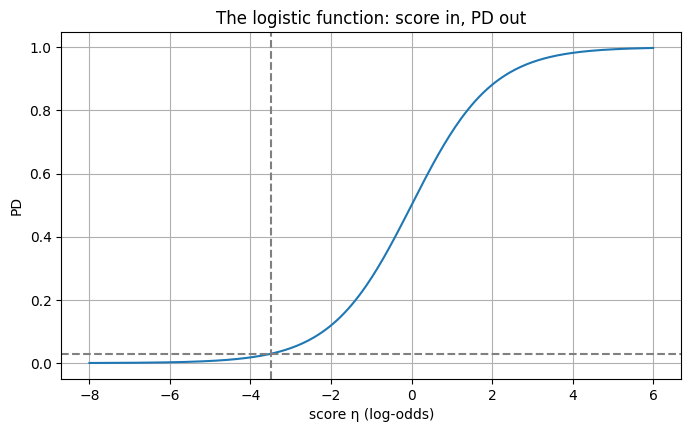

In [4]:
eta = -5 + 3 * 0.5
print('score eta =', eta, '  PD =', round(1 / (1 + np.exp(-eta)), 4))

e = np.linspace(-8, 6, 300)
plt.plot(e, 1 / (1 + np.exp(-e)))
plt.axvline(-3.5, color='grey', ls='--'); plt.axhline(0.029, color='grey', ls='--')
plt.xlabel('score η (log-odds)'); plt.ylabel('PD'); plt.title('The logistic function: score in, PD out'); plt.show()

**Worked exercise.** Same model. What DTI gives a PD of exactly 50%? (Hint: 50% means log-odds of 0, so solve $-5 + 3 \times DTI = 0$. Then check in code.)

<details><summary><b>Show answer</b></summary>

```python
dti = 5 / 3                              # 1.667
print(1 / (1 + np.exp(-(-5 + 3 * dti))))   # 0.5
```
</details>

In [5]:
dti = 5 / 3                              # 1.667
print(1 / (1 + np.exp(-(-5 + 3 * dti))))   # 0.5

0.5


## A4. The normal distribution, z-scores and Φ

**In plain English.** Many quantities in statistics, including estimated coefficients, follow a bell-shaped **normal distribution**. To compare anything against one standard bell curve, we convert it to a **z-score**: how many standard deviations it is from the centre.

**The notation.**
- $N(\mu, \sigma^2)$: a normal distribution with centre $\mu$ (mu) and spread $\sigma$ (sigma).
- $N(0, 1)$: the **standard normal**, centred at 0 with spread 1. $Z \sim N(0,1)$ means "Z follows the standard normal".
- **z-score:** $z = \dfrac{x - \mu}{\sigma}$
- **PDF** (probability density function): the bell curve itself. Its *height* is not a probability; **area under it is**.
- **CDF**, written $\Phi(z)$ ("phi of z"): the area under the bell curve to the **left** of $z$, which equals $P(Z \le z)$.
- $\Phi^{-1}(a)$: works backwards. Give it an area $a$, it returns the $z$.

**A tiny example by hand.** UK men's heights: mean 175 cm, SD 7 cm. Someone 189 cm tall has $z = (189 - 175)/7 = 2$. From tables, $\Phi(2) = 0.977$, so about 97.7% of men are shorter.

**Numbers worth memorising.**

| Fact | Value | Meaning |
|---|---|---|
| $\Phi(0)$ | 0.5 | Half the area is below 0 |
| $\Phi(1.96)$ | 0.975 | 2.5% is above 1.96 |
| $\Phi(-1.96)$ | 0.025 | 2.5% is below −1.96 |
| $\Phi^{-1}(0.975)$ | 1.96 | So 95% lies between −1.96 and +1.96 |

**Physics link.** The PDF is like velocity and the CDF like distance travelled: distance is the area under a velocity–time graph, just as $\Phi$ is the area under the PDF.

z for 189 cm: 2.0    Φ(2) = 0.9772
Φ(1.96) = 0.975    Φ⁻¹(0.975) = 1.96


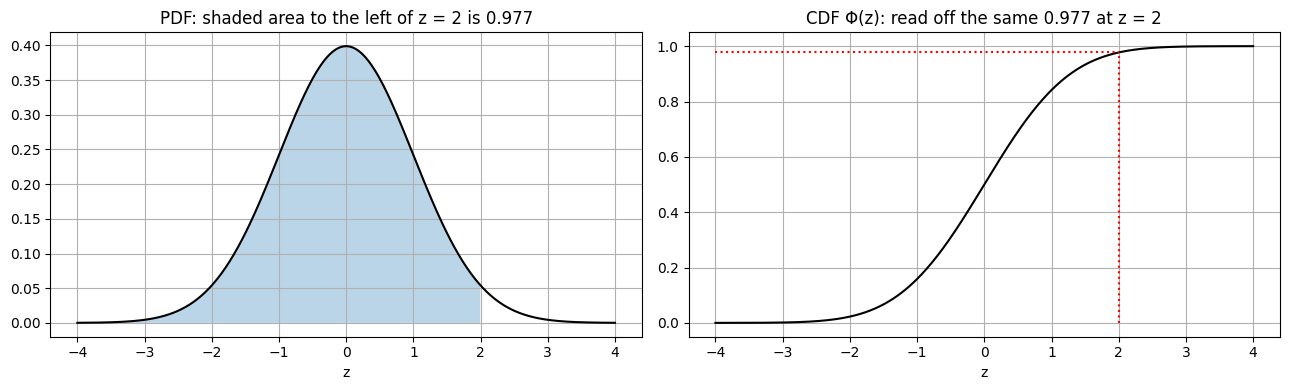

In [36]:
print('z for 189 cm:', (189 - 175) / 7, '   Φ(2) =', round(stats.norm.cdf(2), 4))
print('Φ(1.96) =', round(stats.norm.cdf(1.96), 4), '   Φ⁻¹(0.975) =', round(stats.norm.ppf(0.975), 4))

z = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(z, stats.norm.pdf(z), 'k'); ax[0].fill_between(z, stats.norm.pdf(z), where=z <= 2, alpha=0.3)
ax[0].set_title('PDF: shaded area to the left of z = 2 is 0.977'); ax[0].set_xlabel('z')
ax[1].plot(z, stats.norm.cdf(z), 'k'); ax[1].plot([2, 2], [0, stats.norm.cdf(2)], 'r:'); ax[1].plot([-4, 2], [stats.norm.cdf(2)] * 2, 'r:')
ax[1].set_title('CDF Φ(z): read off the same 0.977 at z = 2'); ax[1].set_xlabel('z')
plt.tight_layout(); plt.show()

**Worked exercise.** What share of the standard normal lies between −1 and +1? Use $\Phi(1) - \Phi(-1)$. (You should get roughly two-thirds.)

<details><summary><b>Show answer</b></summary>

```python
print(stats.norm.cdf(1) - stats.norm.cdf(-1))   # 0.6827
```
</details>

In [37]:
print(stats.norm.cdf(1) - stats.norm.cdf(-1))   # 0.6827

0.6826894921370859


## A5. Standard errors, p-values and confidence intervals

**In plain English.** A coefficient estimated from data, $\hat\beta$, would come out slightly differently if you had a different sample of loans. The **standard error** (SE) measures how much it would wobble. From $\hat\beta$ and its SE you get three things, all answering slightly different questions:

| Quantity | Question it answers | Formula |
|---|---|---|
| **z** | How many SEs is my estimate from zero? | $z = \hat\beta / SE$ |
| **p-value** | If the variable truly had no effect, how often would chance alone give a $z$ at least this far from zero? | $p = 2\,\big(1 - \Phi(\lvert z \rvert)\big)$ |
| **95% CI** | Which true values are consistent with my estimate? | $\hat\beta \pm 1.96 \times SE$ |

Why "2 ×" in the p-value: an estimate could be surprisingly far from zero in either direction, so we count both tails.

**They always agree at the 5% level:** $|z| > 1.96$ ⟺ $p < 0.05$ ⟺ the 95% interval does not contain 0. (⟺ means "exactly when".)

**A tiny example by hand.** $\hat\beta = 0.84$, $SE = 0.28$.
- $z = 0.84 / 0.28 = 3.0$
- $\Phi(3.0) = 0.99865$, so one tail is $0.00135$ and $p = 0.0027$.
- CI $= 0.84 \pm 1.96 \times 0.28 = [0.29,\ 1.39]$, which excludes 0.

**Common mistake.** A p-value is *not* "the probability the variable is useless". It is the probability of data this extreme *if* the variable were useless.

In [38]:
b, se = 0.84, 0.28
z = b / se
p = 2 * (1 - stats.norm.cdf(abs(z)))
ci = (b - 1.96 * se, b + 1.96 * se)
print(f'z = {z:.2f},  p = {p:.4f},  95% CI = [{ci[0]:.2f}, {ci[1]:.2f}]')

z = 3.00,  p = 0.0027,  95% CI = [0.29, 1.39]


**Worked exercise.** Same estimate, 0.84, but now SE = 0.60. Work out z, p and the CI. Is it significant at 5%? Why did a bigger SE change the answer?

<details><summary><b>Show answer</b></summary>

```python
b, se = 0.84, 0.60
z = b / se                                   # 1.4
p = 2 * (1 - stats.norm.cdf(abs(z)))         # 0.16
print(z, p, (b - 1.96 * se, b + 1.96 * se))  # CI about [-0.34, 2.02], contains 0
# Not significant: the estimate is only 1.4 SEs from zero, which chance produces easily.
```
</details>

In [39]:
b, se = 0.84, 0.60
z = b / se                                   # 1.4
p = 2 * (1 - stats.norm.cdf(abs(z)))         # 0.16
print(z, p, (b - 1.96 * se, b + 1.96 * se))  # CI about [-0.34, 2.02], contains 0
# Not significant: the estimate is only 1.4 SEs from zero, which chance produces easily.

1.4 0.16151331846754213 (-0.33599999999999997, 2.016)


## A6. Chi-squared

**In plain English.** Square a z-score and the sign disappears: $(-2)^2 = (+2)^2 = 4$. The pattern that squared z-scores follow is called **chi-squared with 1 degree of freedom**, $\chi^2_1$. Add up $k$ squared z-scores and you get $\chi^2_k$.

**Why bother?** For one coefficient, the z-test and the squared version give exactly the same answer. Squaring matters because it lets you **add** several z's together to test several coefficients at once, which you can't do with signed numbers. SAS calls the squared z the **Wald chi-square**.

**The notation.**

$$W = z^2 = \left(\frac{\hat\beta}{SE}\right)^2 \sim \chi^2_1$$

The 5% cut-off moves from 1.96 to $1.96^2 = 3.84$.

**Physics link.** If a gas molecule's velocity in one direction is normal, its kinetic energy in that direction, $\tfrac12 m v_x^2$, follows $\chi^2_1$. Total kinetic energy across x, y and z follows $\chi^2_3$. Each degree of freedom carries the same average energy, just as the mean of $\chi^2_k$ is $k$.

Share of |Z| > 1.96   : 0.0502
Share of Z² > 1.96²    : 0.0502 <- same event, same number
χ²₁ 95th percentile   : 3.841
p for z = 3: normal route 0.0027  chi-squared route 0.0027


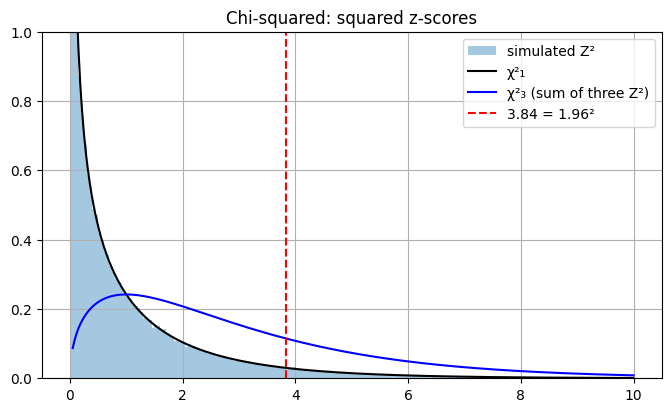

In [40]:
rng = np.random.default_rng(0)
zs = rng.standard_normal(200_000)
print('Share of |Z| > 1.96   :', round((np.abs(zs) > 1.96).mean(), 4))
print('Share of Z² > 1.96²    :', round((zs**2 > 1.96**2).mean(), 4), '<- same event, same number')
print('χ²₁ 95th percentile   :', round(stats.chi2.ppf(0.95, 1), 3))
print('p for z = 3: normal route', round(2 * stats.norm.sf(3), 5), ' chi-squared route', round(stats.chi2.sf(9, 1), 5))

w = np.linspace(0.05, 10, 300)
plt.hist(zs**2, bins=200, range=(0, 10), density=True, alpha=0.4, label='simulated Z²')
plt.plot(w, stats.chi2.pdf(w, 1), 'k', label='χ²₁')
plt.plot(w, stats.chi2.pdf(w, 3), 'b', label='χ²₃ (sum of three Z²)')
plt.axvline(3.84, color='r', ls='--', label='3.84 = 1.96²'); plt.ylim(0, 1); plt.legend(); plt.title('Chi-squared: squared z-scores'); plt.show()

**Interview link (A4–A6):** slide 7's stepwise uses exactly these tests. *"Why is 3.84 the cut-off for SLENTRY = 0.05?"* Because $1.96^2 = 3.84$.

---
# Part B: Slide by slide

## The shared loan book

Every section below uses this synthetic mortgage book, so you can see the ideas on realistic-looking data. Because we generate it ourselves, we know the **true** coefficients and can check every estimate against them.

| Column | Meaning |
|---|---|
| `dti` | Debt-to-income ratio |
| `bti` | Balance-to-income. Built to be almost a copy of `dti`, with **no** effect of its own. Used for VIF. |
| `ltv` | Loan-to-value ratio |
| `months_in_arrears` | Months behind on payments |
| `utilisation` | Share of available credit used. **3% missing**, on purpose. |
| `noise` | Pure random numbers with no effect. Used to show false positives. |
| `default` | 1 if the loan defaulted, else 0 |

Each default is a weighted coin flip: `rng.binomial(1, p)` gives 1 with probability $p$.

In [41]:
TRUE = {'const': -5.0, 'dti': 3.0, 'ltv': 1.5, 'months_in_arrears': 0.9, 'utilisation': 1.2}

def make_book(n, seed, shift=0.0):
    rng = np.random.default_rng(seed)
    dti = rng.normal(0.35 + shift, 0.12, n).clip(0, 1)
    df = pd.DataFrame({
        'account_id': np.arange(n),
        'dti': dti,
        'bti': (dti * 4 + rng.normal(0, 0.08, n)).clip(0, None),
        'ltv': rng.normal(0.75 + shift, 0.15, n).clip(0.1, 1.2),
        'months_in_arrears': rng.poisson(0.3, n),
        'utilisation': rng.beta(2, 5, n),
        'noise': rng.normal(0, 1, n),
    })
    eta = TRUE['const'] + sum(TRUE[k] * df[k] for k in ['dti', 'ltv', 'months_in_arrears', 'utilisation'])
    df['default'] = rng.binomial(1, 1 / (1 + np.exp(-eta)))
    df.loc[rng.random(n) < 0.03, 'utilisation'] = np.nan
    return df

dev = make_book(20000, seed=1)
print(dev.shape, f"| default rate {dev['default'].mean():.2%} | missing utilisation {dev['utilisation'].isna().mean():.1%}")
dev.head()

(20000, 8) | default rate 11.52% | missing utilisation 3.0%


,account_id,dti,bti,ltv,months_in_arrears,utilisation,noise,default
0,0,0.391470,1.530970,0.774786,0,0.079245,0.643342,0
1,1,0.448594,1.918705,0.996873,0,NaN,0.495080,0
2,2,0.389652,1.685250,0.951851,0,0.010900,-0.777803,0
3,3,0.193621,0.740258,0.604987,0,0.050856,-0.014843,0
4,4,0.458643,1.826127,0.577535,0,0.043258,-0.089184,0


---
## B1. Slide 2: PD → grade → capital

**What the slide says.** "Same inputs, same PD, same grade." Grade gets a **zero tolerance** because grade drives capital.

### Step 1: the master scale
Banks don't use every account's own PD for capital. They sort accounts into **grades** using fixed PD boundaries, a **master scale**. Every account in a grade then uses that grade's PD.

| Grade | PD range | Grade PD used for capital |
|---|---|---|
| 5 | 0.5% to 1.0% | 0.75% |
| 6 | 1.0% to 2.5% | 1.70% |

So a PD of 0.99% and a PD of 1.01% land in **different grades** and get different capital, even though they're almost identical.

In [44]:
BOUNDS = np.array([0.0005, 0.001, 0.0025, 0.005, 0.01, 0.025, 0.05, 0.10, 0.20])      # 9 cut-offs -> 10 grades
GRADE_PD = np.array([0.0003, 0.0007, 0.0017, 0.0037, 0.0075, 0.017, 0.037, 0.075, 0.15, 0.35])

def to_grade(pd_):
    # searchsorted finds which slot each PD falls into; +1 makes grades start at 1
    return np.searchsorted(BOUNDS, pd_, side='right') + 1

for p in [0.0003, 0.004, 0.0099999, 0.0100001, 0.3]:
    print(f'PD {p:<10} -> grade {to_grade(p)}')

PD 0.0003     -> grade 1
PD 0.004      -> grade 4
PD 0.0099999  -> grade 5
PD 0.0100001  -> grade 6
PD 0.3        -> grade 10


### Step 2: the capital formula, term by term
For UK residential mortgages under IRB, the capital needed per £1 lent is

$$K = LGD \times \left[\Phi\!\left(\frac{\Phi^{-1}(PD) + \sqrt{R}\;\Phi^{-1}(0.999)}{\sqrt{1-R}}\right) - PD\right]$$

and risk-weighted assets are $RWA = 12.5 \times K \times EAD$.

| Symbol | Meaning | Typical value |
|---|---|---|
| $PD$ | The grade's probability of default | 0.75% |
| $LGD$ | Loss given default: share of the loan lost if it defaults | 20% for mortgages |
| $EAD$ | Exposure at default: how much is owed | £100,000 |
| $R$ | Correlation: how much borrowers suffer together in a downturn | 0.15 for mortgages |
| $\Phi^{-1}(PD)$ | Turns the PD into a z-score | $\Phi^{-1}(0.0075) = -2.43$ |
| $\Phi^{-1}(0.999)$ | A 1-in-1000-year bad economy, as a z-score | 3.09 |
| $\Phi(\dots)$ | Turns the shifted z-score back into a "stressed" PD | |

**In words:** convert the PD to a z-score, push it towards a 1-in-1000-year recession, convert back to get a **stressed PD**, then hold capital for the gap between the stressed loss and the normal expected loss.

**Worked example by hand** (PD = 0.75%, LGD = 20%, R = 0.15):
1. $\Phi^{-1}(0.0075) = -2.432$
2. $\sqrt{0.15}\times 3.090 = 1.197$
3. $(-2.432 + 1.197)/\sqrt{0.85} = -1.340$
4. $\Phi(-1.340) = 0.0902$, the stressed PD (about 12× the normal PD)
5. $K = 0.20 \times (0.0902 - 0.0075) = 0.01654$
6. RWA per £100k $= 12.5 \times 0.01654 \times 100{,}000 = £20{,}650$

In [45]:
def irb_k(pd_, lgd=0.2, R=0.15):
    z = (stats.norm.ppf(pd_) + np.sqrt(R) * stats.norm.ppf(0.999)) / np.sqrt(1 - R)
    return lgd * (stats.norm.cdf(z) - pd_)

for p in [0.0099999, 0.0100001]:
    g = to_grade(p); gpd = GRADE_PD[g - 1]
    print(f'account PD {p:.7f} -> grade {g} -> grade PD {gpd:.4f} -> RWA per £100k £{12.5 * irb_k(gpd) * 100_000:,.0f}')

account PD 0.0099999 -> grade 5 -> grade PD 0.0075 -> RWA per £100k £20,650
account PD 0.0100001 -> grade 6 -> grade PD 0.0170 -> RWA per £100k £35,330


A PD difference of 0.0000002 moved RWA by about £15,000 per £100k lent. **That** is why the reconciliation slide insists on a 100% grade match and special checks for accounts near a boundary.

**Worked exercise.** Write `near_boundary(pd_, tol)` that returns True for any PD within `tol` of any value in `BOUNDS`. Test it on `np.array([0.0099999, 0.02, 0.0500004, 0.3])` with `tol=1e-6`; you should get `[True, False, True, False]`.

<details><summary><b>Show answer</b></summary>

```python
def near_boundary(pd_, tol):
    # distance from every PD (rows) to every boundary (columns)
    dist = np.abs(pd_[:, None] - BOUNDS[None, :])
    return (dist <= tol).any(axis=1)

print(near_boundary(np.array([0.0099999, 0.02, 0.0500004, 0.3]), 1e-6))
```
</details>

In [51]:
def near_boundary(pd_, tol):
    # distance from every PD (rows) to every boundary (columns)
    dist = np.abs(pd_[:, None] - BOUNDS[None, :])
    return (dist <= tol).any(axis=1)

print(near_boundary(np.array([0.0099999, 0.02, 0.0500004, 0.3]), 1e-6))

[ True False  True False]


**Interview link:** *"Why focus on grade rather than PD?"* and *"What about accounts right on a grade boundary?"*

“Because capital is driven by the grade, not the account’s own PD. Every account in a grade uses that grade’s PD in the capital formula. So a tiny PD difference doesn’t matter at all, unless it moves an account into a different grade. Then it changes the capital. In my example, an account at 0.99999% PD sits in grade 5 and needs about £20,650 of RWA per £100k. At 1.00001% it moves to grade 6 and needs about £35,330. A PD difference of 0.0000002 moved RWA by about £15,000. That’s why I’d give PD a tight tolerance, but grade a zero tolerance.”

“That’s the one place a PD difference inside tolerance can still matter. So I’d flag every account whose PD is within the PD tolerance of a boundary, which is 1e-6 in my proposal, and check those individually. If any of them land in a different grade in Python than in SAS, I’d find the root cause and fix it before sign-off, even though the PD difference itself passed. In practice that’s a small number of accounts, so it’s cheap to check, and it closes the only gap between ‘PDs match to tolerance’ and ‘capital matches exactly’.”

---
## B2. Slide 3: Replicate first, why re-fitting changes the model

**What the slide says.** Freeze the SAS coefficients; never re-fit them in Python.

**What "fitting" means.** Fitting chooses the coefficients that make the observed defaults most likely. This is **maximum likelihood estimation (MLE)**. For each loan, the model gives a probability to what actually happened ($p_i$ if it defaulted, $1-p_i$ if not). The **log-likelihood** adds up the logs of those:

$$\ell(\beta) = \sum_{i=1}^{n} \Big[\, y_i \ln p_i + (1 - y_i)\ln(1 - p_i) \,\Big]$$

Read it as: "for each loan, take the log of the probability the model gave to what really happened, and add them all up." The best coefficients make $\ell$ as large (as close to 0) as possible.

**Why two fits can disagree.** There's no formula that gives the answer directly. The computer climbs the hill step by step and **stops when the steps get small enough**. Different software, or different stopping rules, stop at slightly different places. A slightly different data extract moves the hill itself.

**A tiny example by hand.** Three loans: PDs 0.10, 0.60, 0.05; outcomes 0, 1, 0.
$\ell = \ln(0.90) + \ln(0.60) + \ln(0.95) = -0.105 - 0.511 - 0.051 = -0.667$.

In [50]:
p = np.array([0.10, 0.60, 0.05]); y = np.array([0, 1, 0])
print('log-likelihood:', round(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)), 3))

feats = ['dti', 'ltv', 'months_in_arrears', 'utilisation']
d = dev.dropna(subset=['utilisation'])
X_ = sm.add_constant(d[feats]); y_ = d['default']

sas_fit = sm.Logit(y_, X_).fit(disp=0, method='newton', tol=1e-10)           # plays the role of 'SAS'
loose = sm.Logit(y_, X_).fit(disp=0, method='bfgs', gtol=1e-3, maxiter=200)  # different optimiser, looser stop
drop = d.sample(frac=0.995, random_state=0)                                   # 0.5% of rows missing
extract = sm.Logit(drop['default'], sm.add_constant(drop[feats])).fit(disp=0)

print(pd.DataFrame({'SAS (frozen)': sas_fit.params, 'different optimiser': loose.params,
                    'different extract': extract.params, 'TRUE': pd.Series(TRUE)}).round(4))

log-likelihood: -0.667
                   SAS (frozen)  different optimiser  different extract  TRUE
const                   -5.2146              -5.1847            -5.1989  -5.0
dti                      3.3575               3.2787             3.3509   3.0
ltv                      1.6231               1.6622             1.6100   1.5
months_in_arrears        0.9269               0.9183             0.9226   0.9
utilisation              1.0919               1.0324             1.0833   1.2


Now score every loan with each set of coefficients and count how many **grades** change:

In [52]:
frozen = sas_fit.params
pd_sas = 1 / (1 + np.exp(-(X_ @ frozen)))
for name, b in [('different optimiser', loose.params), ('different extract', extract.params)]:
    pd_new = 1 / (1 + np.exp(-(X_ @ b)))
    flips = (to_grade(pd_sas.values) != to_grade(pd_new.values)).sum()
    print(f'{name:22s} biggest PD change {np.abs(pd_sas - pd_new).max():.4f}, grades changed: {flips}')

different optimiser    biggest PD change 0.0119, grades changed: 372
different extract      biggest PD change 0.0039, grades changed: 53


Both re-fits are statistically "the same model", yet they move hundreds of grades. Freezing the coefficients removes the problem: scoring becomes plain arithmetic.

**Worked exercise.** Write `score(df, params)` that returns PDs using frozen `params` (a Series including `'const'`), using only the logistic formula from A3. Check it matches `sas_fit.predict(X_)` with `np.allclose`.

<details><summary><b>Show answer</b></summary>

```python
def score(df, params):
    eta = params['const'] + sum(params[f] * df[f] for f in params.index if f != 'const')
    return 1 / (1 + np.exp(-eta))

print(np.allclose(score(d, frozen), sas_fit.predict(X_)))   # True
```
</details>

In [53]:
def score(df, params):
    eta = params['const'] + sum(params[f] * df[f] for f in params.index if f != 'const')
    return 1 / (1 + np.exp(-eta))

print(np.allclose(score(d, frozen), sas_fit.predict(X_)))   # True

True


**Interview link:** *"Will you re-fit the model in Python at all?"* Only as a test of the estimation code, never to score customers.

Yes, but only as a test. I’d re-run the original development in Python on the original development sample and check the coefficients match SAS to around 1e-6. That proves the estimation code works, so the next redevelopment can be done in Python. But customers are always scored with the frozen SAS coefficients, because a re-fit, however close, is a different model.”

“Because the SAS server is the only place the bank can currently build a model. After switch-off, the next recalibration or redevelopment has to happen in Python, and the stepwise and VIF rules in the brief only exist in estimation. I’d rather prove that code reproduces SAS’s coefficients now, while SAS is still there to check against, than discover a problem the first time monitoring goes red.”

---
## B3. Slide 4: A reproducible pipeline

**What the slide says.** Every PD can be rebuilt from its run ID; parameters live in config; outputs are checksummed.

**Three ideas to understand.**

1. **Config.** Every number the model uses (coefficients, cut-offs, how missing values are treated) lives in one dictionary, not scattered through the code. Change the model = change the config, visibly.
2. **Stages as functions.** Each stage takes the previous stage's output plus the config, and returns a new table. Same input + same config ⟹ same output, every time.
3. **Checksums (hashes).** A hash turns any data into a short "fingerprint". Change even one digit of the data and the fingerprint changes completely. Storing the fingerprint lets anyone prove later that nothing was altered.

In [54]:
print(hashlib.sha256(b'PD = 0.0123').hexdigest()[:16])
print(hashlib.sha256(b'PD = 0.0124').hexdigest()[:16], '<- one digit changed, completely different fingerprint')

277851c8d92791ed
5c9db6502ac56a2d <- one digit changed, completely different fingerprint


In [55]:
CONFIG = {
    'coefs': {k: float(v) for k, v in frozen.items()},
    'util_missing_fill': 0.0,
    'grade_bounds': BOUNDS.tolist(),
}

def checksum(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()[:12]

def st_cleanse(raw, cfg):
    out = raw[['account_id', 'dti', 'ltv', 'months_in_arrears', 'utilisation']].copy()
    out['utilisation'] = out['utilisation'].fillna(cfg['util_missing_fill'])
    return out

def st_score(clean, cfg):
    c = cfg['coefs']
    eta = c['const'] + sum(c[f] * clean[f] for f in c if f != 'const')
    return pd.DataFrame({'account_id': clean['account_id'], 'eta': eta})

def st_pd(scored, cfg):
    return pd.DataFrame({'account_id': scored['account_id'], 'pd': 1 / (1 + np.exp(-scored['eta']))})

def st_grade(pds, cfg):
    g = np.searchsorted(np.array(cfg['grade_bounds']), pds['pd'], side='right') + 1
    return pd.DataFrame({'account_id': pds['account_id'], 'pd': pds['pd'], 'grade': g})

STAGES = [('cleansed', st_cleanse), ('score', st_score), ('pd', st_pd), ('grade', st_grade)]

def run_pipeline(raw, cfg, run_month):
    run_id = f"{run_month}-{hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:8]}"
    outputs, manifest, x = {}, {'run_id': run_id, 'raw': checksum(raw)}, raw
    for name, fn in STAGES:
        x = fn(x, cfg)
        outputs[name] = x
        manifest[name] = checksum(x)
    return outputs, manifest

out1, man1 = run_pipeline(dev, CONFIG, '2026-10')
_, man2 = run_pipeline(dev, CONFIG, '2026-10')
print(json.dumps(man1, indent=1))
print('Run it twice, identical fingerprints:', man1 == man2)

{
 "run_id": "2026-10-2c1f177e",
 "raw": "ed15eb445067",
 "cleansed": "896e641f2c8e",
 "score": "100dc20a6957",
 "pd": "b0badca58c2b",
 "grade": "2039e028f066"
}
Run it twice, identical fingerprints: True


**Worked exercise.** Copy `CONFIG` (use `json.loads(json.dumps(CONFIG))` for a full copy), increase the `ltv` coefficient by 0.01, rerun the pipeline, and list which stage fingerprints changed. You should find `['score', 'pd', 'grade']`: the raw data and cleansing are untouched, and the run ID changes too.

<details><summary><b>Show answer</b></summary>

```python
cfg2 = json.loads(json.dumps(CONFIG))
cfg2['coefs']['ltv'] += 0.01
_, man3 = run_pipeline(dev, cfg2, '2026-10')
print([k for k in ['raw', 'cleansed', 'score', 'pd', 'grade'] if man3[k] != man1[k]])
print(man1['run_id'], '->', man3['run_id'])
```
</details>

In [56]:
cfg2 = json.loads(json.dumps(CONFIG))
cfg2['coefs']['ltv'] += 0.01
_, man3 = run_pipeline(dev, cfg2, '2026-10')
print([k for k in ['raw', 'cleansed', 'score', 'pd', 'grade'] if man3[k] != man1[k]])
print(man1['run_id'], '->', man3['run_id'])

['score', 'pd', 'grade']
2026-10-2c1f177e -> 2026-10-732fba7c


**Interview link:** *"Why store every intermediate stage?"* So a difference can be traced to the exact stage where it starts.

---
## B4. Slide 5: Reconciliation and tolerances

**What the slide says.** Compare SAS and Python at every stage, each with its own tolerance.

**Why exact equality is impossible.** Computers store numbers in binary, which can't represent most decimals exactly.

In [57]:
print('0.1 + 0.2 =', repr(0.1 + 0.2), '   equal to 0.3?', 0.1 + 0.2 == 0.3)
print('difference:', 0.1 + 0.2 - 0.3)

0.1 + 0.2 = 0.30000000000000004    equal to 0.3? False
difference: 5.551115123125783e-17


So two correct programs can differ around the 16th decimal place. Tolerances decide how big a difference is allowed.

**Two kinds of tolerance.** For SAS value $a$ and Python value $b$:

| Type | Passes if | Good for | Example |
|---|---|---|---|
| Absolute | $\lvert a - b \rvert \le \text{atol}$ | Numbers on a known scale (PDs between 0 and 1) | atol = 0.000001 |
| Relative | $\lvert a - b \rvert \le \text{rtol} \times \lvert a \rvert$ | Numbers of any size (balances) | rtol = 0.000000001 |
| Exact | $a = b$ | Categories (bins, grades) | grade 5 vs grade 5 |

**Notation reminder:** `1e-6` means $1 \times 10^{-6} = 0.000001$.

**A tiny example by hand.** PD from SAS 0.0123400, Python 0.0123403. Difference 0.0000003 ≤ 0.000001: **pass**. Balance £250,000.00 vs £250,000.01: difference/size = 0.00000004 > 1e-9: **fail** (relative), which flags a real penny difference.

**The demo.** We simulate a "SAS" run that differs from Python in two ways: harmless floating-point noise everywhere, and one real logic difference (SAS filled missing utilisation with the median; Python fills with 0).

In [58]:
py = run_pipeline(dev, CONFIG, '2026-10')[0]

raw_sas = dev.copy()
raw_sas['utilisation'] = raw_sas['utilisation'].fillna(raw_sas['utilisation'].median())   # the hidden SAS step
sas = run_pipeline(raw_sas, CONFIG, '2026-10')[0]
rng = np.random.default_rng(7)
sas['score'] = sas['score'].assign(eta=sas['score']['eta'] * (1 + rng.normal(0, 1e-14, len(dev))))   # float noise
sas['pd'] = sas['pd'].assign(pd=sas['pd']['pd'] * (1 + rng.normal(0, 1e-14, len(dev))))

TOL = {'cleansed': ('utilisation', 'rtol', 1e-9), 'score': ('eta', 'atol', 1e-8),
       'pd': ('pd', 'atol', 1e-6), 'grade': ('grade', 'exact', 0)}

def reconcile(sas, py):
    rows = []
    for stage, (col, kind, tol) in TOL.items():
        a, b = sas[stage][col].values, py[stage][col].values
        if kind == 'exact':
            bad = a != b
        elif kind == 'atol':
            bad = np.abs(a - b) > tol
        else:
            bad = np.abs(a - b) > tol * np.abs(a)
        rows.append({'stage': stage, 'column': col, 'rule': f'{kind} {tol:g}', 'accounts failing': int(bad.sum())})
    return pd.DataFrame(rows)

reconcile(sas, py)

,stage,column,rule,accounts failing
0,cleansed,utilisation,rtol 1e-09,609
1,score,eta,atol 1e-08,609
2,pd,pd,atol 1e-06,609
3,grade,grade,exact 0,224


The float noise passes everywhere. The real difference fails at **`cleansed`**, the first stage, and then knocks on to every later stage. If you only compared final PDs, you'd see failures but not *where* they came from.

**Worked exercise.** Find the `account_id`s that fail at the `cleansed` stage, and confirm they are exactly the accounts with missing utilisation in `dev`.

<details><summary><b>Show answer</b></summary>

```python
a, b = sas['cleansed'], py['cleansed']
fails = a.loc[np.abs(a['utilisation'] - b['utilisation']) > 1e-9 * np.abs(a['utilisation']), 'account_id']
print(len(fails), set(fails) == set(dev.loc[dev['utilisation'].isna(), 'account_id']))
```
</details>

In [59]:
a, b = sas['cleansed'], py['cleansed']
fails = a.loc[np.abs(a['utilisation'] - b['utilisation']) > 1e-9 * np.abs(a['utilisation']), 'account_id']
print(len(fails), set(fails) == set(dev.loc[dev['utilisation'].isna(), 'account_id']))

609 True


**Interview link:** *"Why 1e-6 for the PD?"* Far above floating-point noise (about 1e-16 relative), far below anything material.

---
## B5. Slide 6: When the numbers differ, SAS vs Python

Each trap below is one row of the slide's table. For each: what happens, why, and the fix.

### Trap 1: missing values
- **SAS:** a missing value counts as **smaller than any number**. So `if dpd < 30` is TRUE for a missing dpd.
- **Python:** `NaN` (not a number) compared with anything gives **False**.
- **Fix:** handle missing values explicitly, and match whatever SAS did.

In [60]:
dpd = pd.Series([0, 45, np.nan, 120])
print(pd.DataFrame({'dpd': dpd, 'Python: dpd < 30': dpd < 30, 'SAS behaviour': dpd.fillna(-np.inf) < 30}))

     dpd  Python: dpd < 30  SAS behaviour
0    0.0              True           True
1   45.0             False          False
2    NaN             False           True
3  120.0             False          False


### Trap 2: rounding
- **SAS `ROUND`:** halves go **away from zero**: 2.5 → 3, −2.5 → −3.
- **Python `round()`:** halves go to the **even** number: 2.5 → 2, 3.5 → 4.
- **Storage makes it worse:** 2.675 is really stored as 2.67499999…, so `round(2.675, 2)` gives 2.67. SAS gives 2.68.
- **numpy is different again:** `np.round(0.047125, 5)` gives 0.04712, while SAS gives 0.04713.
- **Fix:** use Python's `decimal` module with `ROUND_HALF_UP` when matching SAS.

In [61]:
from decimal import Decimal, ROUND_HALF_UP
for v in [0.5, 1.5, 2.5, -2.5]:
    print(f'{v:5}: Python round -> {round(v):2d}')
print('2.675 is really stored as', f'{2.675:.20f}', '-> round(2.675, 2) =', round(2.675, 2))
print('np.round(0.047125, 5) =', np.round(0.047125, 5), '  (SAS would give 0.04713)')

  0.5: Python round ->  0
  1.5: Python round ->  2
  2.5: Python round ->  2
 -2.5: Python round -> -2
2.675 is really stored as 2.67499999999999982236 -> round(2.675, 2) = 2.67
np.round(0.047125, 5) = 0.04712   (SAS would give 0.04713)


**Worked exercise.** Write `sas_round(x, decimals=0)` using `Decimal(str(x)).quantize(...)` with `ROUND_HALF_UP`. Check `sas_round(2.5) == 3`, `sas_round(-2.5) == -3`, `sas_round(2.675, 2) == 2.68` and `sas_round(0.047125, 5) == 0.04713`.

<details><summary><b>Show answer</b></summary>

```python
def sas_round(x, decimals=0):
    q = Decimal(1).scaleb(-decimals)          # 1, 0.1, 0.01, ...
    return float(Decimal(str(x)).quantize(q, rounding=ROUND_HALF_UP))

print(sas_round(2.5), sas_round(-2.5), sas_round(2.675, 2), sas_round(0.047125, 5))
```
</details>

In [62]:
def sas_round(x, decimals=0):
    q = Decimal(1).scaleb(-decimals)          # 1, 0.1, 0.01, ...
    return float(Decimal(str(x)).quantize(q, rounding=ROUND_HALF_UP))

print(sas_round(2.5), sas_round(-2.5), sas_round(2.675, 2), sas_round(0.047125, 5))

3.0 -3.0 2.68 0.04713


### Trap 3: bin edges
- **SAS format `low-<10`:** means "up to but **not including** 10", written $[\text{low}, 10)$. A square bracket includes the end; a round bracket excludes it.
- **Python `pd.cut`:** by default includes the **right** edge, $(\text{low}, 10]$, so 10 lands in a different bin.
- **Fix:** `pd.cut(..., right=False)`.

In [22]:
vals = pd.Series([9.99, 10.0, 10.01])
print(pd.DataFrame({'value': vals, 'pd.cut default': pd.cut(vals, [-np.inf, 10, np.inf]),
                    'SAS-style (right=False)': pd.cut(vals, [-np.inf, 10, np.inf], right=False)}))

   value pd.cut default SAS-style (right=False)
0   9.99   (-inf, 10.0]            [-inf, 10.0)
1  10.00   (-inf, 10.0]             [10.0, inf)
2  10.01    (10.0, inf]             [10.0, inf)


### Trap 4: dates
- **SAS:** a date is stored as the number of days since **1 January 1960**.
- **Python/Unix:** day counts usually start at **1 January 1970**.
- **Fix:** convert with `origin='1960-01-01'`.

In [23]:
sas_days = pd.Series([0, 23741, 24410])
print(pd.to_datetime(sas_days, unit='D', origin='1960-01-01'))
print('Wrong origin gives:', pd.to_datetime(23741, unit='D').date())

0   1960-01-01
1   2024-12-31
2   2026-10-31
dtype: datetime64[ns]
Wrong origin gives: 2035-01-01


### Trap 5: which outcome PROC LOGISTIC models
- **SAS default:** models the probability of the **lower** value, so $P(y = 0)$, "no default".
- **Python:** models $P(y = 1)$, "default".
- **Effect:** every coefficient has the **opposite sign**. **Fix:** check for `DESCENDING` or `EVENT='1'` in the SAS code.

In [24]:
m1 = sm.Logit(d['default'], X_).fit(disp=0)
m0 = sm.Logit(1 - d['default'], X_).fit(disp=0)
print(pd.DataFrame({'models P(default)': m1.params, 'models P(no default), SAS default': m0.params}).round(4))

                   models P(default)  models P(no default), SAS default
const                        -5.2146                             5.2146
dti                           3.3575                            -3.3575
ltv                           1.6231                            -1.6231
months_in_arrears             0.9269                            -0.9269
utilisation                   1.0919                            -1.0919


**Interview link:** *"Give an example of a numerical rather than a logic break."* Rounding, Trap 2.

---
## B6. Slide 7: Stepwise selection and VIF

### Part 1: what stepwise does
**In plain English.** Start with no variables. Repeat two moves until nothing changes:
1. **Entry:** look at every variable not yet in the model. Add the one with the strongest evidence, if its p-value is below 0.05 (SAS calls this SLENTRY).
2. **Removal:** look at every variable already in. Remove the weakest, if its p-value has risen above 0.05 (SAS calls this SLSTAY).

**Which test for which move, and why.**

| Move | Test | Model it needs | Why |
|---|---|---|---|
| Entry | **Score** test | Only the current model, *without* the candidate | Testing 20 candidates needs no extra fits |
| Removal | **Wald** test, $(\hat\beta/SE)^2$ | The current model, *with* the variable | Already fitted, so it's free |

Both give a $\chi^2_1$ statistic, so both compare against 3.84.

**The score test in plain English.** Fit the model without the candidate. Then ask: if we nudged the candidate's coefficient away from zero, how quickly would the fit improve? A steep slope means a big improvement, so a large score statistic. You don't need to memorise its formula; know that it measures **the slope of the log-likelihood at zero**.

$$S = U^\top I^{-1} U, \qquad U = X^\top (y - \tilde p), \qquad I = X^\top \tilde W X$$

($U$ is the slope, $I$ measures curvature, $\tilde p$ are the PDs from the smaller model, and $\tilde W$ has $\tilde p(1-\tilde p)$ on its diagonal.)

In [63]:
def score_test(df, selected, cand):
    yv = df['default'].values
    Xr = sm.add_constant(df[selected]) if selected else pd.DataFrame({'const': np.ones(len(df))}, index=df.index)
    p0 = np.asarray(sm.Logit(yv, Xr).fit(disp=0).predict(Xr))
    Xf = np.column_stack([Xr.values, df[cand].values])
    U = Xf.T @ (yv - p0)
    I = Xf.T @ (Xf * (p0 * (1 - p0))[:, None])
    S = float(U @ np.linalg.solve(I, U))
    return S, stats.chi2.sf(S, 1)

ds = dev.dropna(subset=['utilisation'])

def stepwise(df, candidates, slentry=0.05, slstay=0.05, max_iter=50, verbose=True):
    selected = []
    for step in range(1, max_iter + 1):
        changed = False
        remaining = [c for c in candidates if c not in selected]
        if remaining:
            pvals = {c: score_test(df, selected, c)[1] for c in remaining}
            best = min(pvals, key=pvals.get)
            if verbose:
                print(f'Step {step} entry check: ' + ', '.join(f'{c} p={pvals[c]:.2g}' for c in remaining))
            if pvals[best] < slentry:
                selected.append(best); changed = True
                if verbose: print(f'   -> ADD {best}')
        if selected:
            fit = sm.Logit(df['default'], sm.add_constant(df[selected])).fit(disp=0)
            wp = fit.pvalues.drop('const')
            if wp.max() > slstay:
                if verbose: print(f'   -> REMOVE {wp.idxmax()} (Wald p={wp.max():.2g})')
                selected.remove(wp.idxmax()); changed = True
        if not changed:
            if verbose: print('   -> no change, stop')
            break
    return selected

chosen = stepwise(ds, ['dti', 'bti', 'ltv', 'months_in_arrears', 'utilisation', 'noise'])
print('\nSelected:', chosen)

Step 1 entry check: dti p=3.3e-61, bti p=5.5e-59, ltv p=2.1e-25, months_in_arrears p=2.3e-175, utilisation p=1.1e-12, noise p=0.95
   -> ADD months_in_arrears
Step 2 entry check: dti p=1.5e-64, bti p=2.8e-62, ltv p=6.9e-25, utilisation p=3.8e-14, noise p=0.96
   -> ADD dti
Step 3 entry check: bti p=0.61, ltv p=3.8e-25, utilisation p=1.4e-14, noise p=0.94
   -> ADD ltv
Step 4 entry check: bti p=0.61, utilisation p=1.2e-14, noise p=0.9
   -> ADD utilisation
Step 5 entry check: bti p=0.61, noise p=0.92
   -> no change, stop

Selected: ['months_in_arrears', 'dti', 'ltv', 'utilisation']


Read the trace: each step shows every candidate's p-value. Notice that once `dti` is in, `bti` (its near-copy) has nothing new to add, so it never enters. And `noise` never gets below 0.05 here.

### Part 2: why stepwise p-values are too optimistic
If you test $k$ useless variables, each at 5%, the chance at least one sneaks in by luck is

$$1 - 0.95^k$$

(The chance a single useless variable stays out is 0.95; all $k$ stay out with probability $0.95^k$; subtract from 1.)

In [64]:
for k in [1, 5, 10, 30, 50]:
    print(f'{k:3d} useless candidates -> {1 - 0.95**k:.0%} chance at least one gets in')

  1 useless candidates -> 5% chance at least one gets in
  5 useless candidates -> 23% chance at least one gets in
 10 useless candidates -> 40% chance at least one gets in
 30 useless candidates -> 79% chance at least one gets in
 50 useless candidates -> 92% chance at least one gets in


### Part 3: VIF, what it measures
**In plain English.** If two variables say almost the same thing, the model can't tell which one deserves the credit. Their coefficients become unstable. **VIF** (variance inflation factor) measures how bad this is for each variable.

**How it's calculated.** For variable $j$:
1. Predict variable $j$ using all the *other* variables (an ordinary linear regression).
2. Take the $R^2$ of that regression, $R_j^2$: the share of variable $j$ explained by the others (0 = none, 1 = all of it).
3. $$VIF_j = \frac{1}{1 - R_j^2}$$

**A tiny example by hand.**

| $R_j^2$ | VIF | SE multiplied by $\sqrt{VIF}$ |
|---|---|---|
| 0 | 1 | 1 (no overlap) |
| 0.5 | 2 | 1.41 |
| 0.8 | 5 | 2.24 |
| 0.9 | 10 | 3.16 |

The formula uses **only the predictors**, never the default flag.

In [65]:
def vif(df, cols):
    out = {}
    for j in cols:
        others = [c for c in cols if c != j]
        r2 = sm.OLS(df[j], sm.add_constant(df[others])).fit().rsquared
        out[j] = {'R²': r2, 'VIF': 1 / (1 - r2), 'SE x': np.sqrt(1 / (1 - r2))}
    return pd.DataFrame(out).T

vif(ds, ['dti', 'bti', 'ltv', 'months_in_arrears', 'utilisation']).round(3)

,R²,VIF,SE x
dti,0.973,37.053,6.087
bti,0.973,37.053,6.087
ltv,0.000,1.000,1.000
months_in_arrears,0.000,1.000,1.000
utilisation,0.000,1.000,1.000


### Part 4: what breaks if you ignore VIF
**Bootstrap** means: resample the loan book with replacement many times, refit each time, and look at how much a coefficient jumps around. It's a way of asking "what if we'd had a slightly different sample?"

Below, we refit 200 times with and without the near-duplicate `bti`.

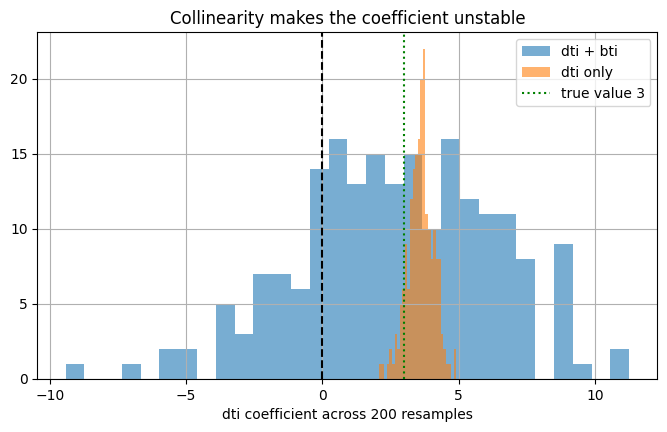

,mean,std,share negative
spec,,,
dti + bti,2.698,3.585,0.2
dti only,3.605,0.477,0.0


In [66]:
rng = np.random.default_rng(3)
small = ds.sample(3000, random_state=0)
rows = []
for _ in range(200):
    s_ = small.sample(len(small), replace=True, random_state=int(rng.integers(1e9)))
    for spec, cols in [('dti only', ['dti', 'ltv', 'months_in_arrears', 'utilisation']),
                       ('dti + bti', ['dti', 'bti', 'ltv', 'months_in_arrears', 'utilisation'])]:
        f = sm.Logit(s_['default'], sm.add_constant(s_[cols])).fit(disp=0)
        rows.append({'spec': spec, 'dti_coef': f.params['dti']})
boot = pd.DataFrame(rows)

for spec, g in boot.groupby('spec'):
    plt.hist(g['dti_coef'], bins=30, alpha=0.6, label=spec)
plt.axvline(0, color='black', ls='--'); plt.axvline(3, color='green', ls=':', label='true value 3')
plt.xlabel('dti coefficient across 200 resamples'); plt.legend(); plt.title('Collinearity makes the coefficient unstable'); plt.show()
summary = boot.groupby('spec')['dti_coef'].agg(['mean', 'std'])
summary['share negative'] = boot.groupby('spec')['dti_coef'].apply(lambda s: (s < 0).mean())
summary.round(3)

With `bti` in the model, the `dti` coefficient spreads out hugely and is **negative** in a sizeable share of samples: more debt appearing to mean *less* risk. That's "signs can flip". A model like that fails expert review.

**Worked exercise.** Compute the ratio of the two standard deviations (with `bti` ÷ without) and compare it with $\sqrt{VIF_{dti}}$ from Part 3. They should be roughly similar: VIF predicted the instability.

<details><summary><b>Show answer</b></summary>

```python
sd = boot.groupby('spec')['dti_coef'].std()
v = vif(ds, ['dti', 'bti', 'ltv', 'months_in_arrears', 'utilisation'])
print(sd['dti + bti'] / sd['dti only'], np.sqrt(v.loc['dti', 'VIF']))
```
</details>

In [67]:
sd = boot.groupby('spec')['dti_coef'].std()
v = vif(ds, ['dti', 'bti', 'ltv', 'months_in_arrears', 'utilisation'])
print(sd['dti + bti'] / sd['dti only'], np.sqrt(v.loc['dti', 'VIF']))

7.517835281702837 6.087122843569448


**Interview link:** all eight questions on slide 7, especially *"Why not just look at the correlation matrix?"* and *"Does multicollinearity bias the predictions?"*

---
## B7. Slide 8: Monitoring

We compare the development book with a **drifted** live book where DTI and LTV have crept up (`shift=0.05`).

In [68]:
live = make_book(20000, seed=99, shift=0.05)
dev_pd = score(dev.fillna({'utilisation': 0}), frozen)
live_pd = score(live.fillna({'utilisation': 0}), frozen)
print(f'average PD: development {dev_pd.mean():.3%}, live {live_pd.mean():.3%}')

average PD: development 11.414%, live 14.048%


### Part 1: PSI (population stability index)
**In plain English.** Has the mix of customers changed since the model was built? Split the score into bins (using the development data), then compare the share of accounts in each bin then and now.

$$PSI = \sum_{\text{bins}} (a - e)\,\ln\!\left(\frac{a}{e}\right)$$

$e$ = share of development accounts in the bin ("expected"); $a$ = share of live accounts ("actual"). Every term is positive or zero, so PSI only grows as things drift.

**A tiny example by hand.** Three bins.

| Bin | $e$ | $a$ | $a - e$ | $\ln(a/e)$ | Term |
|---|---|---|---|---|---|
| Low | 0.5 | 0.4 | −0.1 | −0.223 | 0.0223 |
| Mid | 0.3 | 0.3 | 0 | 0 | 0 |
| High | 0.2 | 0.3 | +0.1 | +0.405 | 0.0405 |
| | | | | **PSI** | **0.063** |

**Rule of thumb:** below 0.10 stable; 0.10 to 0.25 investigate; above 0.25 significant shift.

In [69]:
e = np.array([0.5, 0.3, 0.2]); a = np.array([0.4, 0.3, 0.3])
print('hand example PSI:', round(np.sum((a - e) * np.log(a / e)), 4))

def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

print('score PSI, dev vs live:', round(psi(dev_pd, live_pd), 4))

hand example PSI: 0.0629
score PSI, dev vs live: 0.1439


**Worked exercise.** Compute the PSI of each input (`dti`, `ltv`, `months_in_arrears`, `utilisation`), development vs live, dropping missing values first. Which input drifted most? (It should be one of the two we shifted.)

<details><summary><b>Show answer</b></summary>

```python
input_psi = pd.Series({c: psi(dev[c].dropna(), live[c].dropna()) for c in ['dti', 'ltv', 'months_in_arrears', 'utilisation']})
print(input_psi.round(4)); print('worst:', input_psi.idxmax())
```
</details>

In [70]:
input_psi = pd.Series({c: psi(dev[c].dropna(), live[c].dropna()) for c in ['dti', 'ltv', 'months_in_arrears', 'utilisation']})
print(input_psi.round(4)); print('worst:', input_psi.idxmax())

dti                  0.1773
ltv                  0.1049
months_in_arrears    0.0000
utilisation          0.0004
dtype: float64
worst: dti


### Part 2: Gini and AUC (does the model still rank risk well?)
**In plain English.** Take a random defaulter and a random non-defaulter. **AUC** is the probability the model gave the defaulter the higher PD. 0.5 = coin-toss; 1 = perfect. **Gini** rescales it so 0 = coin-toss and 1 = perfect:

$$Gini = 2 \times AUC - 1$$

**A tiny example by hand.** Two defaulters (PDs 0.9 and 0.35) and two non-defaulters (PDs 0.4 and 0.2). Compare every defaulter–non-defaulter pair:

| Defaulter PD | Non-defaulter PD | Ranked correctly? |
|---|---|---|
| 0.9 | 0.4 | Yes |
| 0.9 | 0.2 | Yes |
| 0.35 | 0.4 | No |
| 0.35 | 0.2 | Yes |

AUC = 3/4 = 0.75, so Gini = 0.5.

In [71]:
def gini(y, p):
    r = stats.rankdata(p)                      # rank every PD from smallest (1) to largest
    n1 = y.sum(); n0 = len(y) - n1
    auc = (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return 2 * auc - 1

print('hand example Gini:', gini(np.array([1, 0, 1, 0]), np.array([0.9, 0.4, 0.35, 0.2])))
print('development Gini :', round(gini(dev['default'].values, dev_pd.values), 4))
print('live Gini        :', round(gini(live['default'].values, live_pd.values), 4))

hand example Gini: 0.5
development Gini : 0.3996
live Gini        : 0.3553


### Part 3: the Jeffreys test (are the PDs still the right size?)
**In plain English.** Gini checks **ranking**. Calibration checks whether the **numbers** are right: if a grade says 2%, do about 2% default? The Jeffreys test asks: given the defaults we actually saw, how plausible is it that the true default rate is at or below the grade's PD?

**The notation.** In a grade with $N$ accounts and $D$ defaults, our uncertainty about the true default rate is described by a **Beta distribution**, a curve for things between 0 and 1:

$$\text{Beta}\big(D + \tfrac12,\; N - D + \tfrac12\big)$$

The p-value is the area of that curve to the **left** of the grade's PD. A **small** p-value means the true rate is very probably **above** the PD: the PD looks too low.

**A tiny example.** Grade PD 2%, 1,000 accounts, 30 defaults (observed 3%).

Jeffreys p-value = 0.0162


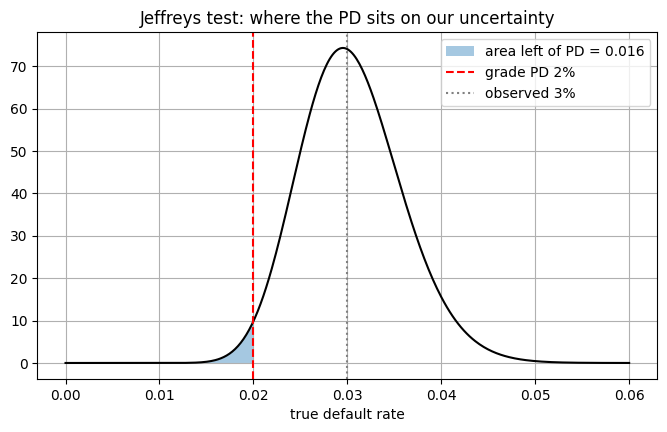

In [34]:
N, D, grade_pd = 1000, 30, 0.02
p_val = stats.beta.cdf(grade_pd, D + 0.5, N - D + 0.5)
print(f'Jeffreys p-value = {p_val:.4f}')

r = np.linspace(0, 0.06, 400)
dens = stats.beta.pdf(r, D + 0.5, N - D + 0.5)
plt.plot(r, dens, 'k'); plt.fill_between(r, dens, where=r <= grade_pd, alpha=0.4, label=f'area left of PD = {p_val:.3f}')
plt.axvline(grade_pd, color='r', ls='--', label='grade PD 2%'); plt.axvline(D / N, color='grey', ls=':', label='observed 3%')
plt.xlabel('true default rate'); plt.legend(); plt.title('Jeffreys test: where the PD sits on our uncertainty'); plt.show()

Only about 1% of the curve lies below 2%, so a 2% PD looks too low for this grade.

In [35]:
t = pd.DataFrame({'grade': to_grade(live_pd.values), 'default': live['default'].values})
by_grade = t.groupby('grade').agg(N=('default', 'size'), D=('default', 'sum'))
by_grade['grade_pd'] = GRADE_PD[by_grade.index - 1]
by_grade['observed_rate'] = by_grade['D'] / by_grade['N']
by_grade['jeffreys_p'] = stats.beta.cdf(by_grade['grade_pd'], by_grade['D'] + 0.5, by_grade['N'] - by_grade['D'] + 0.5)
by_grade['flag'] = np.where(by_grade['jeffreys_p'] < 0.01, 'Red', np.where(by_grade['jeffreys_p'] < 0.05, 'Amber', 'Green'))
by_grade.round(4)

,N,D,grade_pd,observed_rate,jeffreys_p,flag
grade,,,,,,
6,38,3,0.017,0.0789,0.0105,Amber
7,1308,63,0.037,0.0482,0.0193,Amber
8,7176,606,0.075,0.0844,0.0014,Red
9,7719,1104,0.150,0.1430,0.9576,Green
10,3759,1071,0.350,0.2849,1.0000,Green


### Part 4: the one-page RAG table
Put it all together, as on the slide. RAG = Red, Amber, Green. Thresholds here are illustrative.

In [41]:
def rag(value, amber, red):
    return 'Red' if value >= red else 'Amber' if value >= amber else 'Green'

g_dev, g_live = gini(dev['default'].values, dev_pd.values), gini(live['default'].values, live_pd.values)
in_psi = pd.Series({c: psi(dev[c].dropna(), live[c].dropna()) for c in ['dti', 'ltv', 'months_in_arrears', 'utilisation']})
s_psi = psi(dev_pd, live_pd)
pd.DataFrame([
    {'check': 'Score PSI', 'signal': 'Leading', 'value': s_psi, 'status': rag(s_psi, 0.10, 0.25)},
    {'check': f'Worst input PSI ({in_psi.idxmax()})', 'signal': 'Leading', 'value': in_psi.max(), 'status': rag(in_psi.max(), 0.10, 0.25)},
    {'check': 'Missing rate: utilisation', 'signal': 'Leading', 'value': live['utilisation'].isna().mean(), 'status': rag(live['utilisation'].isna().mean(), 0.05, 0.10)},
    {'check': 'Gini relative drop', 'signal': 'Lagging', 'value': 1 - g_live / g_dev, 'status': rag(1 - g_live / g_dev, 0.05, 0.10)},
    {'check': 'Grades failing Jeffreys (p<0.05)', 'signal': 'Lagging', 'value': int((by_grade['jeffreys_p'] < 0.05).sum()), 'status': rag((by_grade['jeffreys_p'] < 0.05).sum(), 1, 3)},
]).round(4)

,check,signal,value,status
0,Score PSI,Leading,0.1439,Amber
1,Worst input PSI (dti),Leading,0.1773,Amber
2,Missing rate: utilisation,Leading,0.0302,Green
3,Gini relative drop,Lagging,0.1108,Red
4,Grades failing Jeffreys (p<0.05),Lagging,3.0000,Red


**Leading vs lagging.** PSI and missing rates are available every month (*leading*: early warning). Gini and the Jeffreys test need defaults to happen, which takes up to 12 months (*lagging*: confirmation).

**Interview link:** every question on slide 8.

---
## B8. Slide 9: The parallel-run exit check

**What the slide says.** Both systems score live data each month. Cut over only after **three consecutive clean months**, not on a fixed date.

"Clean" means zero reconciliation breaks at every stage.

In [42]:
monthly = pd.DataFrame({
    'month':    ['2028-01', '2028-02', '2028-03', '2028-04', '2028-05'],
    'cleansed': [0, 2, 0, 0, 0],
    'pd':       [0, 2, 0, 0, 0],
    'grade':    [1, 1, 0, 0, 0],
})
monthly

,month,cleansed,pd,grade
0,2028-01,0,0,1
1,2028-02,2,2,1
2,2028-03,0,0,0
3,2028-04,0,0,0
4,2028-05,0,0,0


**Worked exercise.** Write `ready_to_cutover(monthly, n=3)` returning True only if the last `n` months have zero breaks in every stage. It should be True for the full table and False for the first four months only.

<details><summary><b>Show answer</b></summary>

```python
def ready_to_cutover(monthly, n=3):
    last = monthly.tail(n).drop(columns='month')
    return len(last) == n and bool((last == 0).all().all())

print(ready_to_cutover(monthly), ready_to_cutover(monthly.iloc[:4]))
```
</details>

In [43]:
def ready_to_cutover(monthly, n=3):
    last = monthly.tail(n).drop(columns='month')
    return len(last) == n and bool((last == 0).all().all())

print(ready_to_cutover(monthly), ready_to_cutover(monthly.iloc[:4]))

True

 False


---
## B9. Slide 10: Capturing the SAS benchmark

**What the slide says.** While both systems still exist, save SAS's outputs at every stage, plus a **manifest**: a list of each file with its fingerprint (hash). Later, anyone can recompute the fingerprints and prove the archive hasn't changed.

In [44]:
archive = tempfile.mkdtemp()
manifest = {'system': 'SAS (simulated)', 'run_month': '2026-10', 'stages': {}}
for stage, frame in sas.items():
    path = os.path.join(archive, f'{stage}.csv')
    frame.to_csv(path, index=False, float_format='%.17g')       # 17 significant figures = full precision
    manifest['stages'][stage] = {'file': f'{stage}.csv', 'rows': len(frame),
                                 'sha256': hashlib.sha256(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open(os.path.join(archive, 'manifest.json'), 'w'), indent=1)
print(json.dumps(manifest, indent=1)[:500], '...')

{
 "system": "SAS (simulated)",
 "run_month": "2026-10",
 "stages": {
  "cleansed": {
   "file": "cleansed.csv",
   "rows": 20000,
   "sha256": "b445fcdf55173e32ffe5f47e076fc45bfe8881dc80bcb43d623a73b2d338130a"
  },
  "score": {
   "file": "score.csv",
   "rows": 20000,
   "sha256": "6c7e199b25f0f0d270adff61e50a1815cf70390978f86a080f04011584550cc7"
  },
  "pd": {
   "file": "pd.csv",
   "rows": 20000,
   "sha256": "070f42133127fcb9eeee69f891c7dca35ad8905d4789651a774a6890f14ee59b"
  },
  "grade": ...


**Worked exercise.** Write `verify_archive(folder)` that reads the manifest, recomputes each file's sha256 and returns `{stage: True/False}`. Then append a line to `pd.csv` and show that only `pd` now fails.

<details><summary><b>Show answer</b></summary>

```python
def verify_archive(folder):
    man = json.load(open(os.path.join(folder, 'manifest.json')))
    return {s: hashlib.sha256(open(os.path.join(folder, i['file']), 'rb').read()).hexdigest() == i['sha256']
            for s, i in man['stages'].items()}

print(verify_archive(archive))
with open(os.path.join(archive, 'pd.csv'), 'a') as f:
    f.write('999999,0.5\n')
print(verify_archive(archive))
```
</details>

In [45]:
def verify_archive(folder):
    man = json.load(open(os.path.join(folder, 'manifest.json')))
    return {s: hashlib.sha256(open(os.path.join(folder, i['file']), 'rb').read()).hexdigest() == i['sha256']
            for s, i in man['stages'].items()}

print(verify_archive(archive))
with open(os.path.join(archive, 'pd.csv'), 'a') as f:
    f.write('999999,0.5\n')
print(verify_archive(archive))

{'cleansed': True, 'score': True, 'pd': True, 'grade': True}
{'cleansed': True, 'score': True, 'pd': False, 'grade': True}


---
# Part C: Summary sheet

| Slide | The idea | The one formula or fact | Your demo result |
|---|---|---|---|
| 2 | Grade drives capital | $K = LGD\,[\Phi(\tfrac{\Phi^{-1}(PD) + \sqrt{R}\,\Phi^{-1}(0.999)}{\sqrt{1-R}}) - PD]$ | A tiny PD change moved RWA by about £15k per £100k |
| 3 | Freeze, don't re-fit | MLE maximises $\ell = \sum [y \ln p + (1-y)\ln(1-p)]$ | Re-fits flipped hundreds of grades |
| 4 | Reproducible runs | Same input + same config ⟹ same fingerprint | A config change altered exactly the downstream stages |
| 5 | Reconcile every stage | $\lvert a-b \rvert \le$ tolerance; grades exact | Break located at the first stage it appears |
| 6 | SAS ≠ Python defaults | Missing < any number in SAS; round-half-even in Python | Each trap reproduced |
| 7 | Stepwise and VIF | Wald $= (\hat\beta/SE)^2$, cut-off 3.84; $VIF = 1/(1-R^2)$ | Near-duplicate variable made a coefficient flip sign |
| 8 | Monitoring | $PSI = \sum (a-e)\ln(a/e)$; $Gini = 2AUC - 1$; Jeffreys uses Beta$(D+\tfrac12, N-D+\tfrac12)$ | Drift traced to the inputs that moved |
| 9 | Parallel run | Three consecutive clean months | Exit check coded |
| 10 | Benchmark | Hash manifest proves the archive | Tampering detected |

**Final check:** for each slide, explain the idea out loud using only this table as a prompt. Where you need to look further up the notebook, that's the section to revisit.